# Chapitre 5 - Exercices 5.1 à 5.6

Ce notebook traite les six premiers exercices du chapitre 5, centrés sur la
réplication à leader unique et le retard de réplication :

- **5.1** : latence d'écriture et durabilité selon le mode de réplication (calcul et
  simulation) ;
- **5.2** : monter un suiveur sur une grosse base : copie, rattrapage et rétention du
  journal (calcul) ;
- **5.3** : régler le délai de basculement et trouver l'anomalie d'un basculement
  (raisonnement et calcul) ;
- **5.4** : quelles instructions peut-on répliquer telles quelles ? Rendre la
  réplication par instructions déterministe (mini-lab) ;
- **5.5** : dimensionner « lire ses écritures » : fenêtre au leader contre jeton de
  position (calcul et simulation) ;
- **5.6** : probabilités des anomalies de lectures monotones et de préfixe cohérent
  (calcul et Monte-Carlo).

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 5.1 : latence d'écriture et durabilité

**Énoncé.** Un leader a trois suiveurs. Les allers-retours leader-suiveur suivent des lois
log-normales (écart-type du logarithme 0,3) de médianes : 1 ms pour le suiveur A (même centre de données),
2 ms pour B (autre centre de données de la même ville), 70 ms pour C (centre de données sur un autre continent).
L'écriture locale du leader prend 0,2 ms.

1. Quel suiveur détermine la latence d'écriture en mode asynchrone, semi-synchrone (un
   acquittement), quorum majoritaire (3 nœuds sur 4, leader compris) et tout synchrone ?
   En déduire les latences médianes approximatives.
2. En asynchrone, le leader reçoit 2 000 écritures/s et le suiveur le plus à jour a en
   moyenne 50 ms de retard. Combien d'écritures confirmées perd-on en moyenne lors d'une
   panne franche du leader ? Avec deux pannes de leader par an ?
3. On veut ne jamais perdre une écriture confirmée **et** survivre à la perte d'un centre de données
   entière. Quel mode choisir, et quelle latence en attendre ?

**Rappels.** Le leader attend le $m$-ième plus petit des allers-retours (statistique
d'ordre) ; en asynchrone, une écriture confirmée n'existe que sur le leader tant qu'elle
n'est pas répliquée (cours 1, sections 2 et 5, section *Synchronous Versus Asynchronous
Replication*).

**Solution.**

*1.* Asynchrone : aucun suiveur, latence ≈ 0,2 ms. Semi-synchrone : le **plus rapide**,
presque toujours A, soit ≈ 1,2 ms. Quorum (2 acquittements de suiveurs) : le
**deuxième** plus rapide, presque toujours B, ≈ 2,2 ms. Tout synchrone : le **plus
lent**, C, ≈ 70 ms.

*2.* Les écritures perdues sont celles validées pendant la fenêtre de retard du meilleur
suiveur : $\lambda \times \bar L = 2\,000 \times 0{,}05 = 100$ écritures par panne, soit
environ 200 par an. (Si le suiveur promu n'est pas le plus à jour, davantage.)

*3.* Il faut qu'une écriture confirmée existe **hors du centre de données du leader** : le
semi-synchrone ne suffit pas (l'acquittement vient presque toujours de A, au même
endroit). Le quorum de la question 1 attend A **et** B : B étant dans un autre centre de données, toute
écriture confirmée survit à la perte du centre de données du leader, pour ≈ 2,2 ms. Il faut aussi
que le basculement promeuve un suiveur qui a l'écriture (le plus à jour).

**Vérification par simulation.**

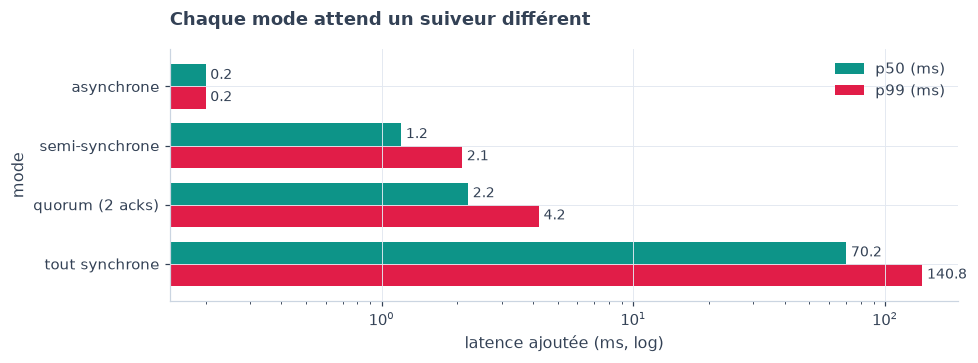

écritures perdues par panne (simulation, retard exponentiel de moyenne 50 ms) : 100


,suiveur déterminant (le plus souvent),p50 (ms),p99 (ms)
mode,,,
asynchrone,aucun,0.20,0.20
semi-synchrone,A,1.20,2.09
quorum (2 acks),B,2.21,4.22
tout synchrone,C,70.19,140.81


In [2]:
n = 200000
med = np.array([1.0, 2.0, 70.0])
rtt = rng.lognormal(np.log(med), 0.3, (n, 3))
rows = []
for mode, lab in [("async", "asynchrone"), ("semisync", "semi-synchrone"), ("quorum", "quorum (2 acks)"), ("sync", "tout synchrone")]:
    lat = rp.write_latency_samples(mode, 3, rtt, local=0.2)
    qui = "aucun" if mode == "async" else "ABC"[np.bincount(np.argsort(rtt, axis=1)[:, rp.needed_acks(mode, 3) - 1]).argmax()]
    rows.append({"mode": lab, "suiveur déterminant (le plus souvent)": qui, "p50 (ms)": np.median(lat), "p99 (ms)": np.percentile(lat, 99)})
R = pd.DataFrame(rows).set_index("mode")
ax = R[["p50 (ms)", "p99 (ms)"]].plot.barh(figsize=(9, 3.4), color=[TEAL, ROSE], width=0.75, logx=True)
annotate_bars(ax, "{:.1f}")
ax.invert_yaxis(); ax.set_xlabel("latence ajoutée (ms, log)")
ax.set_title("Chaque mode attend un suiveur différent")
plt.tight_layout(); plt.show()
perdues = [2000 * rng.exponential(0.05) for _ in range(20000)]
print(f"écritures perdues par panne (simulation, retard exponentiel de moyenne 50 ms) : {np.mean(perdues):.0f}")
R.round(2)

Les chiffres simulés confirment les médianes calculées ; le p99 du quorum reste vers
4 ms, alors que le tout synchrone paie plus de 140 ms au p99 à cause du suiveur
lointain.

> **À retenir.** Le mode de réplication revient à choisir **quel** suiveur on attend :
> c'est sa position (centre de données, continent) qui fixe à la fois la latence et la panne à laquelle
> survivent les écritures confirmées.